# 08 · Tuning, diagnostics & model selection

**Where we are:** logistic regression ranks buyers best (mean AUC 0.754 vs. 0.735 for a hand-regularised LightGBM, notebook 06). The two-part model ranks spend best, by a small margin (notebook 07).

**This notebook's questions:**
1. **Tuning:** with a proper, honest search, does LightGBM catch up?
2. **Diagnosis:** is the model limited by *bias* (too simple / features lacking) or *variance* (too little data)? Learning curves.
3. **Feature selection:** which feature *families* earn their place? Permutation importance vs. group ablation.
4. **Direction of effects:** what does the model actually do with each feature? SHAP.
5. **Selection:** the final configuration that notebook 12 will refit and test once.

### The honesty problem with tuning
Every time we pick the best of many configurations on a fold, that fold's score becomes **optimistic**: some of the "best" is luck. So:
- **Tune on the Sep, Oct and Nov folds only** (expanding-window time CV, notebook 03).
- **Confirm on the December fold**, which the search never sees. If a tuned gain doesn't survive December, it was probably noise.
- **No early stopping on the validation fold:** that would pick the number of trees by peeking at the score we report. The number of trees is tuned like any other hyperparameter.

### 🧠 Predict first
1. After tuning, will LightGBM beat logistic regression? What do you think the tuned trees will look like: deep or shallow?
2. Would **doubling the data** help logistic regression? Would it help an untuned LightGBM?
3. Which feature family matters most: RFM, tenure, timing, rates, basket?

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

sys.path.insert(0, str(Path.cwd().parent))
from src.clean import CLEAN_PARQUET
from src.split import time_folds, monthly_cutoffs
from src.features import CATALOG
from src.preprocess import MODEL_INPUTS, NUM_FEATURES
from src.models import make_logreg, make_lgbm_classifier, make_lgbm_log, run_folds, per_fold, LGBM_BASE

pd.set_option("display.width", 170)
warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
np.random.seed(SEED)

PROCESSED = Path(CLEAN_PARQUET).parent
table = pd.read_parquet(PROCESSED / "features.parquet")
FOLDS = time_folds(monthly_cutoffs("2010-09", "2010-12"))
TUNE_FOLDS, CONFIRM_FOLDS = FOLDS[:3], FOLDS[3:]
print("Tune on:", [v.strftime("%b %Y") for _, v in TUNE_FOLDS], "| confirm on:", [v.strftime("%b %Y") for _, v in CONFIRM_FOLDS])


def auc_by_fold(make_model, folds=FOLDS, data=table) -> pd.Series:
    return per_fold(run_folds(data, make_model, "y_buy", folds), roc_auc_score)

Tune on: ['Sep 2010', 'Oct 2010', 'Nov 2010'] | confirm on: ['Dec 2010']


## 1. Tuning LightGBM (Optuna, tuned on Sep–Nov)

**What each hyperparameter controls** (bias ↔ variance):
| Hyperparameter | Higher value → | Range searched |
|---|---|---|
| `num_leaves` | more complex trees, more interactions (variance ↑) | 3–31 |
| `min_child_samples` | each leaf needs more rows, so smoother (variance ↓) | 20–500 |
| `learning_rate` × `n_estimators` | how far boosting fits (too far → overfit) | 0.01–0.1 × 100–800 |
| `reg_lambda` | L2 shrinkage of leaf values (variance ↓) | 0.001–30 |
| `subsample`, `colsample_bytree` | random rows / features per tree, decorrelates trees (variance ↓) | 0.5–1, 0.4–1 |

**Why Optuna (TPE) over grid or random search:** it learns from previous trials which regions look promising, so 40 trials go further than 40 random ones.
**Alternative not picked:** `RandomizedSearchCV`. Fine, but it needs a custom splitter for our time folds and doesn't adapt.

In [2]:
def lgbm_space(trial) -> dict:
    return dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        num_leaves=trial.suggest_int("num_leaves", 3, 31),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 500, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
    )


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(lambda t: auc_by_fold(lambda: make_lgbm_classifier(**lgbm_space(t)), TUNE_FOLDS)["mean"], n_trials=40)
BEST_LGBM = study.best_params
print(f"Best mean AUC on tuning folds: {study.best_value:.4f}")
pd.Series(BEST_LGBM).to_frame("tuned").join(pd.Series(LGBM_BASE).to_frame("hand-set (06)"))

Best mean AUC on tuning folds: 0.7384


,tuned,hand-set (06)
learning_rate,0.015211,0.03
n_estimators,200.000000,300.00
num_leaves,3.000000,15.00
min_child_samples,230.000000,100.00
reg_lambda,5.188610,1.00
colsample_bytree,0.699167,0.80
subsample,0.840205,0.80


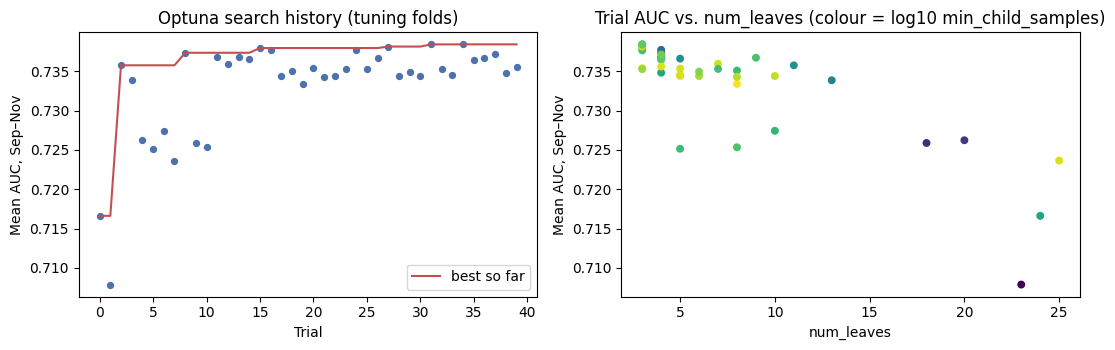

In [3]:
trials = study.trials_dataframe()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].scatter(trials["number"], trials["value"], s=18, color="#4C72B0")
axes[0].plot(trials["number"], trials["value"].cummax(), color="#C44E52", label="best so far")
axes[0].set_title("Optuna search history (tuning folds)")
axes[0].set_xlabel("Trial")
axes[0].set_ylabel("Mean AUC, Sep–Nov")
axes[0].legend()
axes[1].scatter(trials["params_num_leaves"], trials["value"], c=np.log10(trials["params_min_child_samples"]), cmap="viridis", s=22)
axes[1].set_title("Trial AUC vs. num_leaves (colour = log10 min_child_samples)")
axes[1].set_xlabel("num_leaves")
axes[1].set_ylabel("Mean AUC, Sep–Nov")
plt.tight_layout()
plt.show()

**Takeaway:** the search drives LightGBM toward **very small trees** (a handful of leaves, hundreds of rows per leaf). Trials with many leaves score clearly worse.
A boosted model of tiny trees is close to an **additive** model: a sum of simple step functions, one feature (or one pair) at a time. In other words, the data is telling us **there's little interaction signal to exploit**.
That's consistent with logistic regression doing so well.

### Confirm on December (never seen by the search)

In [4]:
C_GRID = [0.01, 0.1, 1.0, 10.0]
lr_c = pd.DataFrame({C: auc_by_fold(lambda: make_logreg(C=C)) for C in C_GRID}).T
lr_c["tune mean (Sep–Nov)"] = lr_c[["Sep", "Oct", "Nov"]].mean(axis=1)
print("Logistic regression: regularisation strength C (smaller = stronger)")
display(lr_c.round(4))

confirm = pd.DataFrame({
    "LightGBM hand-set (06)": auc_by_fold(make_lgbm_classifier),
    "LightGBM tuned": auc_by_fold(lambda: make_lgbm_classifier(**BEST_LGBM)),
    "logistic regression (C=1)": auc_by_fold(make_logreg),
}).T
confirm.round(4)

Logistic regression: regularisation strength C (smaller = stronger)


,Sep,Oct,Nov,Dec,mean,tune mean (Sep–Nov)
0.01,0.7320,0.7352,0.7551,0.7797,0.7505,0.7407
0.10,0.7289,0.7356,0.7546,0.7809,0.7500,0.7397
1.00,0.7359,0.7411,0.7570,0.7812,0.7538,0.7446
10.00,0.7383,0.7421,0.7572,0.7814,0.7548,0.7459


,Sep,Oct,Nov,Dec,mean
LightGBM hand-set (06),0.7104,0.7207,0.7377,0.7709,0.7349
LightGBM tuned,0.7346,0.7328,0.7479,0.7762,0.7479
logistic regression (C=1),0.7359,0.7411,0.7570,0.7812,0.7538


In [5]:
def paired_auc_diff(make_a, make_b, n_boot: int = 1000) -> tuple:
    a = run_folds(table, make_a, "y_buy", CONFIRM_FOLDS).sort_values("Customer ID")
    b = run_folds(table, make_b, "y_buy", CONFIRM_FOLDS).sort_values("Customer ID")
    y, pa, pb = a["y"].values, a["pred"].values, b["pred"].values
    rng = np.random.default_rng(SEED)
    diffs = [roc_auc_score(y[i], pa[i]) - roc_auc_score(y[i], pb[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))]
    return roc_auc_score(y, pa) - roc_auc_score(y, pb), *np.quantile(diffs, [0.025, 0.975])


d, lo, hi = paired_auc_diff(make_logreg, lambda: make_lgbm_classifier(**BEST_LGBM))
print(f"Dec: logistic regression − tuned LightGBM = {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

Dec: logistic regression − tuned LightGBM = +0.0051  95% CI [-0.0015, +0.0106]


**Takeaways:**
- **Tuning helped LightGBM in every fold, including December** (+0.005 to +0.024), so the gain is real, not search noise.
- **It still doesn't beat logistic regression, but it gets close.** The mean gap shrinks from about 0.019 to 0.006. Logistic regression is still ahead in every fold (by only 0.001 in September),
  and in December the paired 95% CI for the difference **includes zero**: after tuning, the two are statistically tied on the confirmation fold.
- **Why still choose logistic regression?** It ties or wins everywhere, has about 20 coefficients instead of 200 trees, and is easier to explain and monitor. **When two models tie, choose the simpler one.**
- **Logistic regression's C barely matters** (all within about 0.008). Weak regularisation is fine because the model has only about 20 coefficients for about 11k rows.
  We keep **C = 1**: the tuning-fold winner (C = 10) is better by less than 0.002, which is noise.
- **Interview line:** *"I tuned the GBM with Optuna on earlier time folds and confirmed on a later fold. Tuning pushed it toward tiny, almost additive trees and halved the gap, but logistic regression still won. On this data the signal is mostly monotone and additive."*

## 2. Bias or variance? Learning curves (December fold)
Train on a random share of **customers** (all of a customer's snapshots stay together), score on December. Repeat with 3 seeds.
- **Train and validation both low and close together** → **bias**: more data won't help; we need better features or a more flexible model.
- **Train much higher than validation, and validation still rising** → **variance**: more data or more regularisation will help.

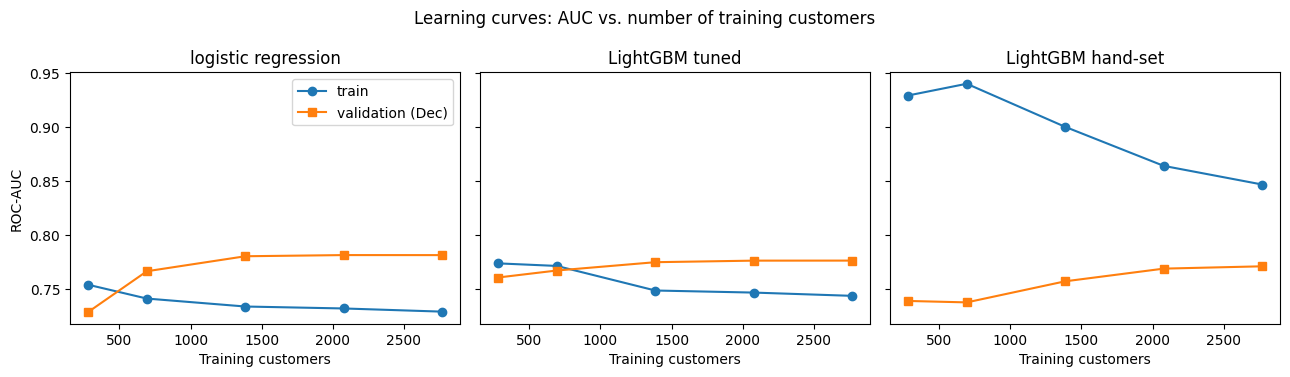

train                                           validation                                   
model LightGBM hand-set LightGBM tuned logistic regression LightGBM hand-set LightGBM tuned logistic regression
frac                                                                                                           
0.10              0.929          0.774               0.754             0.739          0.760               0.728
0.25              0.940          0.771               0.741             0.737          0.767               0.766
0.50              0.900          0.748               0.734             0.757          0.775               0.780
0.75              0.864          0.747               0.732             0.769          0.776               0.781
1.00              0.847          0.744               0.729             0.771          0.776               0.781

In [6]:
train_cuts, v = CONFIRM_FOLDS[0]
tr, va = table[table["cutoff"].isin(train_cuts)], table[table["cutoff"] == v]
customers = tr["Customer ID"].unique()
fracs = [0.1, 0.25, 0.5, 0.75, 1.0]
models = {"logistic regression": make_logreg, "LightGBM tuned": lambda: make_lgbm_classifier(**BEST_LGBM),
          "LightGBM hand-set": make_lgbm_classifier}
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, make in models.items():
        for frac in fracs:
            for seed in range(3):
                keep = np.random.default_rng(seed).choice(customers, int(len(customers) * frac), replace=False)
                sub = tr[tr["Customer ID"].isin(keep)]
                m = make().fit(sub[MODEL_INPUTS], sub["y_buy"])
                rows.append({"model": name, "frac": frac,
                             "train": roc_auc_score(sub["y_buy"], m.predict_proba(sub[MODEL_INPUTS])[:, 1]),
                             "validation": roc_auc_score(va["y_buy"], m.predict_proba(va[MODEL_INPUTS])[:, 1])})
lc = pd.DataFrame(rows).groupby(["model", "frac"])[["train", "validation"]].mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, name in zip(axes, models):
    d = lc.loc[name]
    ax.plot(d.index * len(customers), d["train"], marker="o", label="train")
    ax.plot(d.index * len(customers), d["validation"], marker="s", label="validation (Dec)")
    ax.set_title(name)
    ax.set_xlabel("Training customers")
axes[0].set_ylabel("ROC-AUC")
axes[0].legend()
fig.suptitle("Learning curves: AUC vs. number of training customers")
plt.tight_layout()
plt.show()
lc.unstack(0).round(3)

**Takeaways:**
- **Logistic regression: bias-limited.** Validation AUC is flat from about half the customers onward. More data of the same kind won't help; better *information* would.
  (Validation is *above* training: December has many long-dormant customers who are easy to rank low, as noted in notebook 05.)
- **Hand-set LightGBM: variance-limited.** Training AUC is far above validation, and validation is still climbing at 100%. It would benefit from more data, or from regularisation.
- **Tuned LightGBM:** the train–validation gap is mostly closed, and it also plateaus. Tuning bought what more data would have.
- **So what would actually move the needle?** Not more rows, but **new information**: product mix, marketing contact, web activity. At ARQ: app sessions, balance trends, salary deposits, FX quote views.

## 3. Which features earn their place?
Two tools that answer different questions:
- **Permutation importance:** shuffle **one** feature in the validation data and measure the AUC drop. Cheap, model-agnostic, but **understates** features that have stand-ins (shuffle `spend_90d` and the model still has `spend_180d`).
- **Group ablation:** **remove a whole family** (by neutralising it), **retrain**, and score on all 4 folds. Expensive, but it answers the real question: *does this family add information the others don't?*

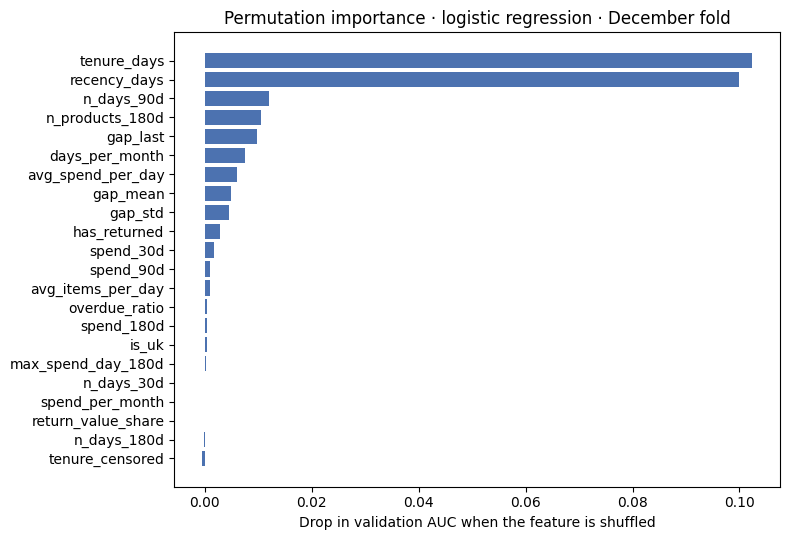

In [7]:
lr_fit = make_logreg().fit(tr[MODEL_INPUTS], tr["y_buy"])
perm = permutation_importance(lr_fit, va[MODEL_INPUTS], va["y_buy"], scoring="roc_auc", n_repeats=5, random_state=SEED)
perm_s = pd.Series(perm.importances_mean, index=MODEL_INPUTS).drop(["country", "Customer ID"]).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(perm_s.index, perm_s.values, color="#4C72B0")
ax.set_title("Permutation importance · logistic regression · December fold")
ax.set_xlabel("Drop in validation AUC when the feature is shuffled")
plt.tight_layout()
plt.show()

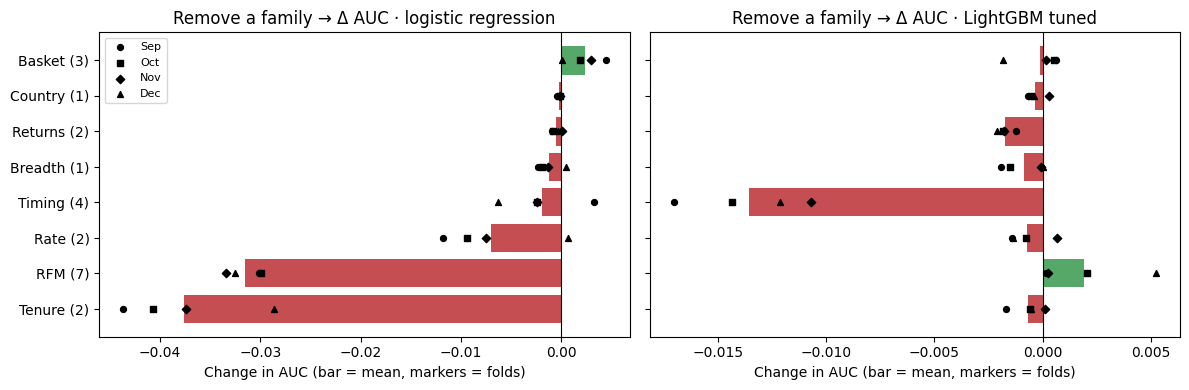

logistic regression                                 LightGBM tuned                                
                            Sep     Oct     Nov     Dec    mean            Sep     Oct     Nov     Dec    mean
Basket (3)               0.0044  0.0019  0.0030  0.0001  0.0024         0.0006  0.0005  0.0002 -0.0018 -0.0001
Breadth (1)             -0.0023 -0.0019 -0.0013  0.0005 -0.0012        -0.0019 -0.0015 -0.0001  0.0000 -0.0009
Country (1)             -0.0004 -0.0001 -0.0001 -0.0002 -0.0002        -0.0007 -0.0006  0.0003 -0.0004 -0.0003
RFM (7)                 -0.0301 -0.0299 -0.0334 -0.0325 -0.0315         0.0001  0.0021  0.0003  0.0052  0.0019
Rate (2)                -0.0117 -0.0094 -0.0074  0.0006 -0.0070        -0.0014 -0.0008  0.0007 -0.0014 -0.0007
Returns (2)             -0.0009 -0.0008  0.0001 -0.0003 -0.0005        -0.0012 -0.0018 -0.0018 -0.0021 -0.0017
Tenure (2)              -0.0437 -0.0407 -0.0374 -0.0287 -0.0376        -0.0017 -0.0006  0.0001 -0.0006 -0.0007
Timing (4)               0.0032 -0.0024 -0.0024 -0.0062 -0.0019        -0.0170 -0.0143 -0.0107 -0.0121 -0.0135

In [8]:
family = CATALOG.set_index("feature")["family"]
families = sorted(set(family[NUM_FEATURES + ["is_uk"]]))


def ablation(make_model) -> pd.DataFrame:
    base = auc_by_fold(make_model)
    out = {}
    for fam in families:
        cols = [c for c in NUM_FEATURES + ["is_uk"] if family[c] == fam]
        out[f"{fam} ({len(cols)})"] = auc_by_fold(make_model, data=table.assign(**{c: 0.0 for c in cols})) - base
    return pd.DataFrame(out).T


abl = {"logistic regression": ablation(make_logreg), "LightGBM tuned": ablation(lambda: make_lgbm_classifier(**BEST_LGBM))}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, a) in zip(axes, abl.items()):
    a = a.sort_values("mean")
    ax.barh(a.index, a["mean"], color=np.where(a["mean"] < 0, "#C44E52", "#55A868"))
    for f, m in zip(["Sep", "Oct", "Nov", "Dec"], "osD^"):
        ax.scatter(a[f], a.index, marker=m, s=18, color="black", zorder=3, label=f if name == "logistic regression" else None)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Remove a family → Δ AUC · {name}")
    ax.set_xlabel("Change in AUC (bar = mean, markers = folds)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.concat(abl, axis=1).round(4)

**Takeaways:**
- **The two models lean on different families.** Logistic regression loses the most without **tenure** and **RFM**. Tuned LightGBM barely misses tenure or RFM; it loses the most without **timing** (gap features, overdue ratio).
  LightGBM can rebuild recency/frequency information from the timing and rate features with step functions; logistic regression can't combine them that way.
  **Importance is a property of a model + feature set, not of a feature alone.** Asking "which feature matters?" without naming the model is ill-posed.
- **Permutation importance can mislead in both directions.** It ranks individual spend features near zero (each has stand-ins), yet group ablation shows the RFM family matters (−0.03).
  And it puts tenure and recency at about −0.10 each, far more than ablation's estimate for tenure (−0.03 in December). Shuffling one feature creates **impossible customers**
  (a 6-month tenure combined with a gap history that implies years), and the model's answers on those inflate the drop. Ablation retrains and asks the cleaner question.
- **Logistic regression's reliance on tenure is a risk to note.** Notebook 04 flagged tenure as the one feature that grows with available history (≤ 190 days in training, up to 555 at test).
  It extrapolated fine to December (up to 373 days), but in notebook 12 we'll check performance by tenure band.
- **Removing the basket family *helps* logistic regression slightly in every fold.** Under our rule (adopt a change only if it wins or ties in every fold), we drop it from the logistic model.
  It's a small gain, but a simpler model at no cost.
- Country (`is_uk`), returns and breadth contribute ≈ 0 for both. They're kept for now (harmless), and candidates for removal in a production model.

In [9]:
BASKET = tuple(c for c in NUM_FEATURES if family[c] == "Basket")
final_lr = pd.DataFrame({"logistic regression, all features": auc_by_fold(make_logreg),
                         "logistic regression, without basket": auc_by_fold(lambda: make_logreg(exclude=BASKET))}).T
final_lr.round(4)

,Sep,Oct,Nov,Dec,mean
"logistic regression, all features",0.7359,0.7411,0.7570,0.7812,0.7538
"logistic regression, without basket",0.7403,0.7429,0.7599,0.7814,0.7561


## 4. Direction of effects: SHAP (tuned LightGBM, December)
Importance says *how much*; SHAP says *which way*. For each customer, SHAP splits the prediction (in log-odds) into one contribution per feature, so contributions add up to the prediction.
LightGBM computes exact TreeSHAP values natively (`pred_contrib=True`), so no extra library is needed.

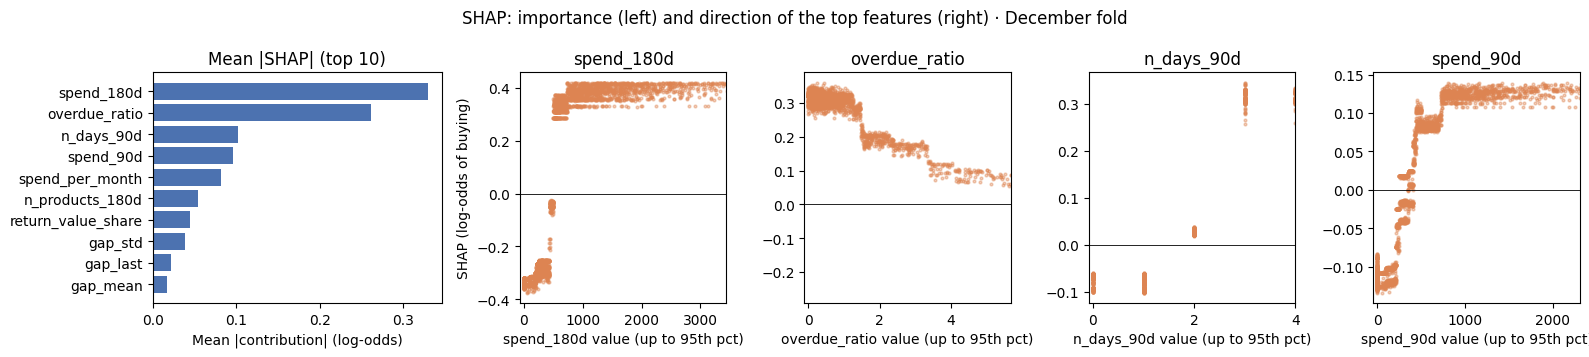

In [10]:
lgbm_fit = make_lgbm_classifier(**BEST_LGBM).fit(tr[MODEL_INPUTS], tr["y_buy"])
X_va = lgbm_fit[0].transform(va[MODEL_INPUTS])
names = lgbm_fit[0].get_feature_names_out()
shap = lgbm_fit[-1].booster_.predict(X_va, pred_contrib=True)[:, :-1]  # last column = bias term
shap_df = pd.DataFrame(shap, columns=names)
X_df = pd.DataFrame(X_va, columns=names)
mean_abs = shap_df.abs().mean().sort_values(ascending=False)
top = mean_abs.index[:4].tolist()

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1.4, 1, 1, 1, 1]})
axes[0].barh(mean_abs.index[:10][::-1], mean_abs.values[:10][::-1], color="#4C72B0")
axes[0].set_title("Mean |SHAP| (top 10)")
axes[0].set_xlabel("Mean |contribution| (log-odds)")
for ax, f in zip(axes[1:], top):
    x = X_df[f]
    ax.scatter(x, shap_df[f], s=4, alpha=0.4, color="#DD8452")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xlim(x.min() - 0.02 * (x.quantile(0.95) - x.min()), x.quantile(0.95))  # zoom: 95% of customers
    ax.set_title(f)
    ax.set_xlabel(f"{f} value (up to 95th pct)")
axes[1].set_ylabel("SHAP (log-odds of buying)")
fig.suptitle("SHAP: importance (left) and direction of the top features (right) · December fold")
plt.tight_layout()
plt.show()

**Takeaway:** the tuned LightGBM has essentially learned **a few yes/no rules**, and their directions match the business story from notebooks 02 and 04:
- **`spend_180d`:** one big step at about **£600 in the last 6 months**: below → about −0.3 log-odds; above → about +0.4. Beyond that, *how much* barely matters for **whether** they buy.
- **`overdue_ratio`:** declines in **stairs** as a customer falls further behind their usual rhythm (about +0.3 when on time, about +0.1 at 3–5× their usual gap). The strongly negative region (about −0.25) belongs to the most-overdue 5%, beyond this zoomed view.
  That's notebook 04's threshold behaviour, in finer detail.
- **`n_days_90d`:** 0–1 purchase days in the last quarter → slightly negative; **3 or more** → about +0.3. Being a *regular* buyer recently is what counts, not a single visit.
- **`spend_90d`:** rises in steps up to about £700, then flat: the same "enough to count as active" shape.
- Every curve is a **step**, which is exactly what a sum of 3-leaf trees produces. It's also why logistic regression keeps up: the signal is "active / not active / overdue", which a linear score captures well.
- Note that recency itself isn't in the top 10 here: its information is already carried by `spend_180d`, `n_days_90d` and the overdue ratio (the redundancy again).

**Caveat:** with correlated features, SHAP splits credit among them somewhat arbitrarily (the same issue as coefficients in notebook 05). Read *directions* and *shapes*, not exact sizes, and never "feature X causes Y".

## 5. Tuning the spend model: a lesson in optimism
The two-part spend model's "how much" part (LightGBM on log spend, buyers only) gets the same treatment: tune on Sep–Nov (25 trials, objective = the two-part model's Spearman), confirm on December.

In [11]:
p_buy = run_folds(table, make_logreg, "y_buy", FOLDS)


def hurdle_spearman(params: dict, folds) -> pd.Series:
    spend = run_folds(table, lambda: make_lgbm_log(**params), "y_spend", folds, train_filter=lambda d: d["y_spend"] > 0)
    p = p_buy[p_buy["fold"].isin(spend["fold"].unique())]
    return per_fold(spend.assign(pred=p["pred"].values * spend["pred"].values), lambda y, q: spearmanr(y, q).correlation)


spend_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
spend_study.optimize(lambda t: hurdle_spearman(lgbm_space(t), TUNE_FOLDS)["mean"], n_trials=25)
spend_cmp = pd.DataFrame({"spend|buy hand-set": hurdle_spearman({}, FOLDS),
                          "spend|buy tuned": hurdle_spearman(spend_study.best_params, FOLDS)}).T
spend_cmp.round(4)

,Sep,Oct,Nov,Dec,mean
spend|buy hand-set,0.5471,0.5330,0.5358,0.5598,0.5439
spend|buy tuned,0.5485,0.5455,0.5463,0.5587,0.5497


**Takeaway:** tuning improves the three folds it was tuned on, and **does nothing for December**, the fold it never saw. That's the **optimism of tuning** made visible:
part of the "gain" on the tuning folds was the search fitting their noise. **Decision:** keep the hand-set spend model, because the tuned gain didn't survive confirmation.
(Most of the two-part model's *ranking* comes from P(buy) anyway; the spend part mainly sets the scale.)

## 6. Final selection for notebook 12

In [12]:
import json

final_config = {
    "buy_model": {"type": "logistic regression", "C": 1.0, "exclude": list(BASKET), "preprocess": "median fill, no skew transform, standardise, is_uk"},
    "spend_if_buy_model": {"type": "LightGBM on log1p(spend), buyers only, smearing on buyers", "params": "LGBM_BASE (hand-set)"},
    "spend_model": "two-part: P(buy) × spend|buy",
    "runner_up_buy": {"type": "LightGBM", "params": BEST_LGBM},
    "level_calibration": "prior shift of P(buy) and seasonal scaling of spend, from the same season one year earlier",
    "final_refit_cutoffs": "2010-01-09 … 2010-12-09 (labels matured by the test cutoff)",
    "features_held_out": ["spend_trend", "days_trend", "history_days", "peak_days_in_window"],
}
(PROCESSED / "final_config.json").write_text(json.dumps(final_config, indent=2, default=str))
print(json.dumps(final_config, indent=2, default=str))

{
  "buy_model": {
    "type": "logistic regression",
    "C": 1.0,
    "exclude": [
      "avg_spend_per_day",
      "max_spend_day_180d",
      "avg_items_per_day"
    ],
    "preprocess": "median fill, no skew transform, standardise, is_uk"
  },
  "spend_if_buy_model": {
    "type": "LightGBM on log1p(spend), buyers only, smearing on buyers",
    "params": "LGBM_BASE (hand-set)"
  },
  "spend_model": "two-part: P(buy) \u00d7 spend|buy",
  "runner_up_buy": {
    "type": "LightGBM",
    "params": {
      "learning_rate": 0.015210816029786018,
      "n_estimators": 200,
      "num_leaves": 3,
      "min_child_samples": 230,
      "reg_lambda": 5.188609692432592,
      "colsample_bytree": 0.6991672345969353,
      "subsample": 0.8402051260786113
    }
  },
  "level_calibration": "prior shift of P(buy) and seasonal scaling of spend, from the same season one year earlier",
  "final_refit_cutoffs": "2010-01-09 \u2026 2010-12-09 (labels matured by the test cutoff)",
  "features_held_out": [

| Decision | Choice | Evidence | Alternative not picked |
|---|---|---|---|
| Buy model | logistic regression, C = 1, without basket features | best in all 4 folds; tuned LightGBM closes half the gap but not all | tuned LightGBM (runner-up) |
| Spend model | two-part: logistic P(buy) × hand-set LightGBM-log spend\|buy | best Gini; beats naive on Spearman in all folds (07) | Tweedie (close, simpler); tuned spend\|buy (gain didn't survive Dec) |
| Hyperparameters | tuned on Sep–Nov, confirmed on Dec | tuned gains that fail confirmation are rejected | tuning on all 4 folds (no honest check left) |
| Feature set | notebook 05's set minus basket (for logistic) | group ablation, all folds | permutation importance alone (misses redundancy) |
| Held-out features | trend, peak-season, history length stay **out** of the final refit | never validated; adding untested features at the final step means testing something we never evaluated | adding them because the Jul–Dec cutoffs could now learn them |

**What notebook 12 will do (once):** refit the chosen models on all 12 cutoffs of 2010, score the June 2011 test cutoff, calibrate the level with the same-season (June 2010) rates,
report bootstrap CIs, deciles, and error by segment (tenure band, country, wholesale vs. small), and turn it into decisions: CAC caps and retention targeting.

### 🧠 Interpret
1. Check your predictions: did tuned LightGBM beat logistic regression? What did the tuned trees look like, and what does that say about the data?
2. Read the learning curves aloud as you would in an interview: which model is bias-limited, which is variance-limited, and what would you invest in next?
3. Why did tenure matter a lot for logistic regression but not for LightGBM? What does that imply about asking "which feature is most important?"
4. The spend tuning "improved" Sep–Nov but not December. Explain the optimism of tuning to a junior DS, and why we kept the untuned model.
5. **ARQ:** the learning curves say "more of the same data won't help". Name three *new* signals ARQ has that this retailer doesn't, and which feature family each would strengthen.